# Banka Pazarlama MLOps Projesi

Bu projede UCI Bank Marketing veri seti kullanilarak bir musterinin vadeli mevduat acip acmayacagi tahmin edilmektedir.
Verideki dengesizlik (imbalance) ele alinmis, pipeline olusturulmus ve en iyi model kaydedilmistir.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, f1_score, precision_recall_curve, roc_curve
import joblib

import warnings
warnings.filterwarnings('ignore')

C:\Users\silak\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\silak\AppData\Local\Temp\matplotlib-00di3y_h because there was an issue with the default path (C:\Users\silak\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1. Veri Yukleme

In [2]:
# Veri noktalı virgul ile ayrilmis
url = 'https://raw.githubusercontent.com/mustafagurbuz06/mlops-workflow/main/data/bank-additional-full.csv'
df = pd.read_csv(url, sep=';')
print('Veri boyutu:', df.shape)
df.head()

Veri boyutu: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Sinif Dengesizligi (EDA)

y
no     36548
yes     4640
Name: count, dtype: int64
Abone olma orani: % 11.27


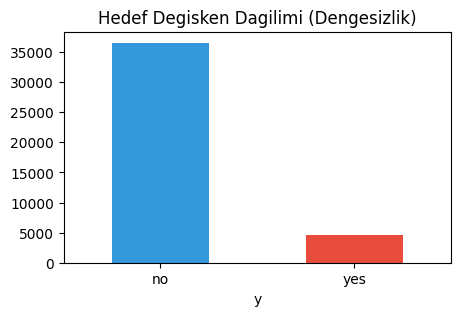

In [3]:
# Hedef degisken dagilimi
print(df['y'].value_counts())
print('Abone olma orani: %', round((df['y'] == 'yes').mean() * 100, 2))

# Grafik
df['y'].value_counts().plot(kind='bar', color=['#3498db', '#e74c3c'], figsize=(5, 3))
plt.title('Hedef Degisken Dagilimi (Dengesizlik)')
plt.xticks(rotation=0)
plt.show()

Burada onemli bir nokta var: Musterilerin yaklasik %89'u 'no', sadece %11'i 'yes'.
Dolayisiyla siradan accuracy metrigi yerine ROC-AUC ve F1-Score metriklerine bakmaliyiz.

## 3. Ozellik Muhendisligi ve Pipeline Hazirligi

In [4]:
df_model = df.copy()

# pdays 999 degeri daha once hic aranmamis demek
df_model['was_contacted'] = (df_model['pdays'] != 999).astype(int)

# Hedef degiskeni 0 ve 1 yapalim
y = (df_model['y'] == 'yes').astype(int)
X = df_model.drop(columns=['y'])

# Sayisal ve kategorik sutunlar
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

## 4. Modellerin Egitilmesi ve Karsilastirma

In [5]:
# 1. Model: Dersteki standart Logistic Regression
lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipe.fit(X_train, y_train)
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]
lr_preds = lr_pipe.predict(X_test)

# 2. Model: Sınıf dengesizligine karsi 'class_weight=balanced' kullanan Random Forest
rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_pipe.fit(X_train, y_train)
rf_probs = rf_pipe.predict_proba(X_test)[:, 1]

# 3. Threshold (Esik degeri) Optimizasyonu:
# Standart 0.5 esigi yerine F1 skorunu maksimize eden esigi bulalim
precisions, recalls, thresholds = precision_recall_curve(y_test, rf_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]
rf_preds_opt = (rf_probs >= best_threshold).astype(int)

In [6]:
# Sonuclari karsilastiralim
ozet = pd.DataFrame({
    'Model': ['Temel Logistic Regression', 'Dengelenmis Random Forest + Esik Ayari'],
    'ROC-AUC': [roc_auc_score(y_test, lr_probs), roc_auc_score(y_test, rf_probs)],
    'F1 Skoru': [f1_score(y_test, lr_preds), f1_score(y_test, rf_preds_opt)],
    'Karar Esigi': [0.50, round(best_threshold, 2)]
})
ozet

,Model,ROC-AUC,F1 Skoru,Karar Esigi
0,Temel Logistic Regression,0.942414,0.540721,0.50
1,Dengelenmis Random Forest + Esik Ayari,0.949482,0.665067,0.67


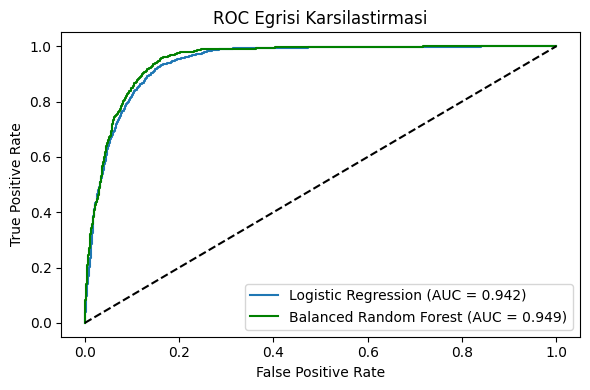

In [7]:
# ROC Egrisi Grafigi
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

plt.figure(figsize=(6, 4))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Balanced Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Egrisi Karsilastirmasi')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Modeli Kaydetme (MLOps Icin)

In [8]:
# En iyi modeli kaydediyoruz
joblib.dump(rf_pipe, 'model.joblib')
print('model.joblib basariyla kaydedildi!')

model.joblib basariyla kaydedildi!


In [9]:
# Modeli yukleyip test edelim
model = joblib.load('model.joblib')
ornek_musteri = X_test.iloc[0:1]
tahmin_olasilik = model.predict_proba(ornek_musteri)[0][1]
tahmin = 1 if tahmin_olasilik >= best_threshold else 0

print('Ornek musteri icin tahmin:', 'Abone Olur' if tahmin == 1 else 'Abone Olmaz')
print(f'Olasilik: {tahmin_olasilik:.2%}')

Ornek musteri icin tahmin: Abone Olmaz
Olasilik: 11.90%
